In [1]:
import itertools
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from multiprocess.pool import Pool

from parity_code import CodeCapacityNoiseModel, LhzLegEncoding
from parity_code.decoders.base import SymmetryMatchingDecoderBase
from parity_code.decoders.common import remove_even_occurrences
from parity_code.decoders_compiled import ComponentPostProcessing

Run the following commands for generating the MWPM and ISM data of Figure 4. MWPM refers to the GSM decoder. The data for random matching and for the lower bound is generated below, within this notebook.

```bash
python simulations/code_capacity/logical_error_rate_gsm.py --distances 11 31 51 --error-rates 0.10 0.51 0.02 --shots 50000 --output simulations/code_capacity/Fig-4-matching-benchmark/data/gsm_pp.csv
python simulations/code_capacity/logical_error_rate_ism.py --distances 11 31 51 --error-rates 0.10 0.51 0.02 --shots 50000 --output simulations/code_capacity/Fig-4-matching-benchmark/data/ism_pp.csv
```

In [2]:
DATA_DIR = Path("data")

# same distances, error rates and shots as in the commands above
DISTANCES = [11, 31, 51]
ERROR_RATES = np.arange(0.10, 0.51, 0.02)
SHOTS = 50000

## Random matching

Random matching replaces MWPM or ISM in the first step of the decoder: the defects along each real symmetry are paired up at random, without any minimization. If a symmetry has an odd number of defects, a randomly chosen one of them is connected to the virtual stabilizer at a randomly chosen end of the symmetry. The activated virtual stabilizers are then paired up at random along the virtual symmetry. Like any matching along the symmetries, this returns the code to the codespace, but usually with a logical error on top, which the post-processing has to remove.

The paper doesn't specify the random matching further. Here, a symmetry with an even number of defects is never connected to its virtual stabilizers. The decoder is only meant for code-capacity noise, where all defects lie in a single time slice.

In [3]:
class RandomMatchingDecoder(SymmetryMatchingDecoderBase):
    """
    Two-step decoder with random matching in the first step, see the description above. Only for
    code-capacity noise: all defects have to lie in a single time slice.

    Args:
        See `SymmetryMatchingDecoderBase`.

        seed (int | None): Seed of the random number generator used for the pairing.
    """

    def __init__(self, *args, seed: int | None = None, **kwargs):
        super().__init__(*args, **kwargs)
        self.rng = np.random.default_rng(seed)

        self._detectors_of_real_symmetries_np = {
            s: np.array(detectors, dtype=int)
            for s, detectors in self.detectors_of_real_symmetries.items()
        }
        # position of every (real or virtual) measurement qubit along each symmetry
        self._index_on_symmetry = {
            s: {qbt: i for i, qbt in enumerate(qbts)}
            for s, qbts in self.measurement_qubits_of_symmetry.items()
        }

    def _path(self, symmetry: int, a: tuple, b: tuple) -> list:
        """Edges of the path between the detectors a and b (in the same time slice) along the
        symmetry, every edge oriented along the symmetry."""
        qbts = self.measurement_qubits_of_symmetry[symmetry]
        index = self._index_on_symmetry[symmetry]
        x_a, y_a, t = a
        x_b, y_b, _ = b
        i, j = sorted((index[(x_a, y_a)], index[(x_b, y_b)]))
        return [((*qbts[k], t), (*qbts[k + 1], t)) for k in range(i, j)]

    def _match(self, syndrome: np.ndarray) -> list:
        matches = []
        added_virtual_detectors = []

        # random matching along each real symmetry
        for s, detectors in self._detectors_of_real_symmetries_np.items():
            defects = [
                self.detector_coords[d] for d in self.rng.permutation(detectors[syndrome[detectors]])
            ]
            if len(defects) % 2 == 1:
                # connect the last defect of the random order to a random end of the symmetry
                x, y, t = defects.pop()
                end_x, end_y = self.measurement_qubits_of_symmetry[s][[0, -1][self.rng.integers(2)]]
                matches.extend(self._path(s, (x, y, t), (end_x, end_y, t)))
                added_virtual_detectors.append((end_x, end_y, t))
            for a, b in zip(defects[::2], defects[1::2]):
                matches.extend(self._path(s, a, b))

        # random matching along the virtual symmetry; every defect lies on two real symmetries, so an
        # even number of virtual detectors has been activated
        order = self.rng.permutation(len(added_virtual_detectors))
        virtual_detectors = [added_virtual_detectors[i] for i in order]
        for a, b in zip(virtual_detectors[::2], virtual_detectors[1::2]):
            matches.extend(self._path(0, a, b))

        # The paths of random pairs overlap a lot. All edges lie in one time slice, so the correction
        # only depends on the edges used an odd number of times; dropping the others is much faster.
        return remove_even_occurrences(matches)

In [4]:
def run_random_matching(args: tuple[int, float, int]) -> tuple[int, float, float, int, bool]:
    """Same as `run_single_simulation` of simulations/code_capacity/logical_error_rate_gsm.py,
    with random matching instead of GSM and post-processing always applied. The matched edges of the
    random matching are post-processed with the compiled post-processing (`ComponentPostProcessing`),
    in batches of shots."""
    distance, p, num_shots = args
    code = LhzLegEncoding(num_logical_qubits=distance)
    ideal_circuit = code.create_stim_circuit(rounds=1)
    circuit = CodeCapacityNoiseModel(bit_flip_prob=p).add_noise_to_circuit(ideal_circuit)
    dem = circuit.detector_error_model(approximate_disjoint_errors=True)

    decoder = RandomMatchingDecoder(
        dem,
        data_qubit_coords=code.base_qubit_coords + code.parity_qubit_coords,
        measurement_qubits_of_symmetry=code.measurement_qubits_of_symmetry,
        boundary_edges_of_real_symmetry=code.boundary_edges_of_symmetry,
        one_lines=code.one_lines,
    )

    sampler = circuit.compile_detector_sampler()
    syndromes, actual_obs = sampler.sample(shots=num_shots, separate_observables=True)

    post_processing = ComponentPostProcessing(decoder)
    data_qubit_coords = code.base_qubit_coords + code.parity_qubit_coords
    base_indices = [data_qubit_coords.index(coord) for coord in code.base_qubit_coords]
    predictions = np.zeros((num_shots, distance), dtype=bool)
    batch_size = 1000
    for start in range(0, num_shots, batch_size):
        batch = syndromes[start : start + batch_size]
        matches = [decoder._match(syndrome) for syndrome in batch]
        shot_offsets = np.cumsum([0] + [len(m) for m in matches])
        point_a = [post_processing.point(a) for m in matches for a, _ in m]
        point_b = [post_processing.point(b) for m in matches for _, b in m]
        corrections = post_processing.unpack(post_processing(point_a, point_b, shot_offsets))
        predictions[start : start + len(batch)] = corrections[:, base_indices]

    num_errors = np.sum(np.any(predictions != actual_obs, axis=1))
    return (distance, p, num_errors / num_shots, num_shots, True)

In [5]:
# The simulation takes a while, so it only runs if there is no data yet; delete the csv file to rerun it.
random_path = DATA_DIR / "random_pp.csv"
if not random_path.exists():
    task_args = list(itertools.product(DISTANCES, ERROR_RATES, [SHOTS]))
    with Pool(processes=5) as pool:
        results = pool.map(run_random_matching, task_args)
    df = pd.DataFrame(results, columns=["distance", "p_phys", "p_log", "num_shots", "post_processing"])
    random_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(random_path, index=False)

## Lower bound

Probability that at least one 1-line contains a logical error, i.e. that half or more of its qubits are flipped. The optimal decoder fails whenever this happens, so this is a lower bound on its failure rate. Under code-capacity noise every data qubit is flipped independently with probability $p$, so the errors are sampled directly.

In [6]:
def one_line_lower_bound(
    distance: int, p: float, num_shots: int, rng: np.random.Generator, batch_size: int = 10000
) -> float:
    """Monte-Carlo estimate of the probability that at least one 1-line contains a logical error."""
    code = LhzLegEncoding(num_logical_qubits=distance)
    data_qubit_coords = code.base_qubit_coords + code.parity_qubit_coords
    qubit_index = {coord: i for i, coord in enumerate(data_qubit_coords)}
    # column i is the mask of the data qubits on 1-line i
    one_lines = np.zeros((len(data_qubit_coords), len(code.one_lines)), dtype=np.float32)
    for i, line in enumerate(code.one_lines.values()):
        one_lines[[qubit_index[coord] for coord in line], i] = 1
    line_lengths = one_lines.sum(axis=0)

    num_failures = 0
    for start in range(0, num_shots, batch_size):
        errors = rng.random((min(batch_size, num_shots - start), len(data_qubit_coords))) < p
        overlaps = errors @ one_lines  # number of flipped qubits on each 1-line
        num_failures += np.sum(np.any(2 * overlaps >= line_lengths, axis=1))
    return num_failures / num_shots

In [7]:
lower_bound_path = DATA_DIR / "lower_bound.csv"
if not lower_bound_path.exists():
    rng = np.random.default_rng()
    rows = [
        (d, p, one_line_lower_bound(d, p, SHOTS, rng), SHOTS)
        for d, p in itertools.product(DISTANCES, ERROR_RATES)
    ]
    df = pd.DataFrame(rows, columns=["distance", "p_phys", "p_log", "num_shots"])
    lower_bound_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(lower_bound_path, index=False)

In [8]:
# import data from csv files, MWPM refers to the GSM decoder; post-processing is applied for all matchings
data = {
    "MWPM": pd.read_csv(DATA_DIR / "gsm_pp.csv"),
    "ISM": pd.read_csv(DATA_DIR / "ism_pp.csv"),
    "Random matching": pd.read_csv(DATA_DIR / "random_pp.csv"),
    "Lower bound": pd.read_csv(DATA_DIR / "lower_bound.csv"),
}

# Figure 4:
Code failure rate (probability that at least one of the $d$ logical qubits is flipped) of the two-step decoder with MWPM, ISM or random matching in the first step, and post-processing in all cases, compared with the lower bound.

In [9]:
# color, line style and marker per decoder; the lower bound is a reference line without markers
STYLES = {
    "MWPM":            dict(color="blue", linestyle='solid',   marker='o', linewidth=3, markersize=10),
    "ISM":             dict(color="green", linestyle='dotted',  marker='s', linewidth=3, markersize=10),
    "Random matching": dict(color="red", linestyle='dashdot', marker='D', linewidth=3, markersize=10),
    "Lower bound":     dict(color="#494845", linestyle='dashed',  linewidth=4, zorder=1),
}
Y_MIN = 5.0E-3
Y_LABEL = (5.3E-3, 7.0E-3)  # bottom and top of the distance labels

def plot_matching_benchmark(data, ax, save_path=None):
    for d in DISTANCES:
        for label, df in data.items():
            sub = df[df['distance'] == d].sort_values('p_phys')
            ax.plot(sub['p_phys'], sub['p_log'], label=label if d == DISTANCES[0] else None, **STYLES[label])

        # label each distance right of where its curves enter the plot, where the families are furthest
        # apart; the label starts right of where the curves cross its top edge
        mwpm = data["MWPM"][(data["MWPM"]['distance'] == d) & (data["MWPM"]['p_log'] > 0)].sort_values('p_phys')
        p_label = np.interp(np.log(Y_LABEL[1]), np.log(mwpm['p_log']), mwpm['p_phys'])
        ax.annotate(f'd={d}', (p_label, Y_LABEL[0]), xytext=(6, 0), textcoords='offset points',
                    fontsize=24, ha='left', va='bottom')

    ax.legend(loc='lower right', prop={'size': 28})
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.xlabel('Physical error probability', size=28)
    plt.ylabel('Code failure rate', size=28)
    plt.xlim(0.1, 0.5)
    plt.ylim(Y_MIN, 1.1)
    plt.yscale('log')
    # Thicker box around plot (spines)
    for spine in ax.spines.values():
        spine.set_linewidth(3)  # Adjust thickness as needed
    # Thicker major ticks
    ax.tick_params(axis='both', which='major', width=3, length=12)  # length is optional
    # Thicker minor ticks
    ax.tick_params(axis='both', which='minor', width=1.5, length=8)  # Adjust as needed
    if save_path is not None:
        ax.figure.savefig(save_path, format='pdf', bbox_inches='tight')
    plt.show()

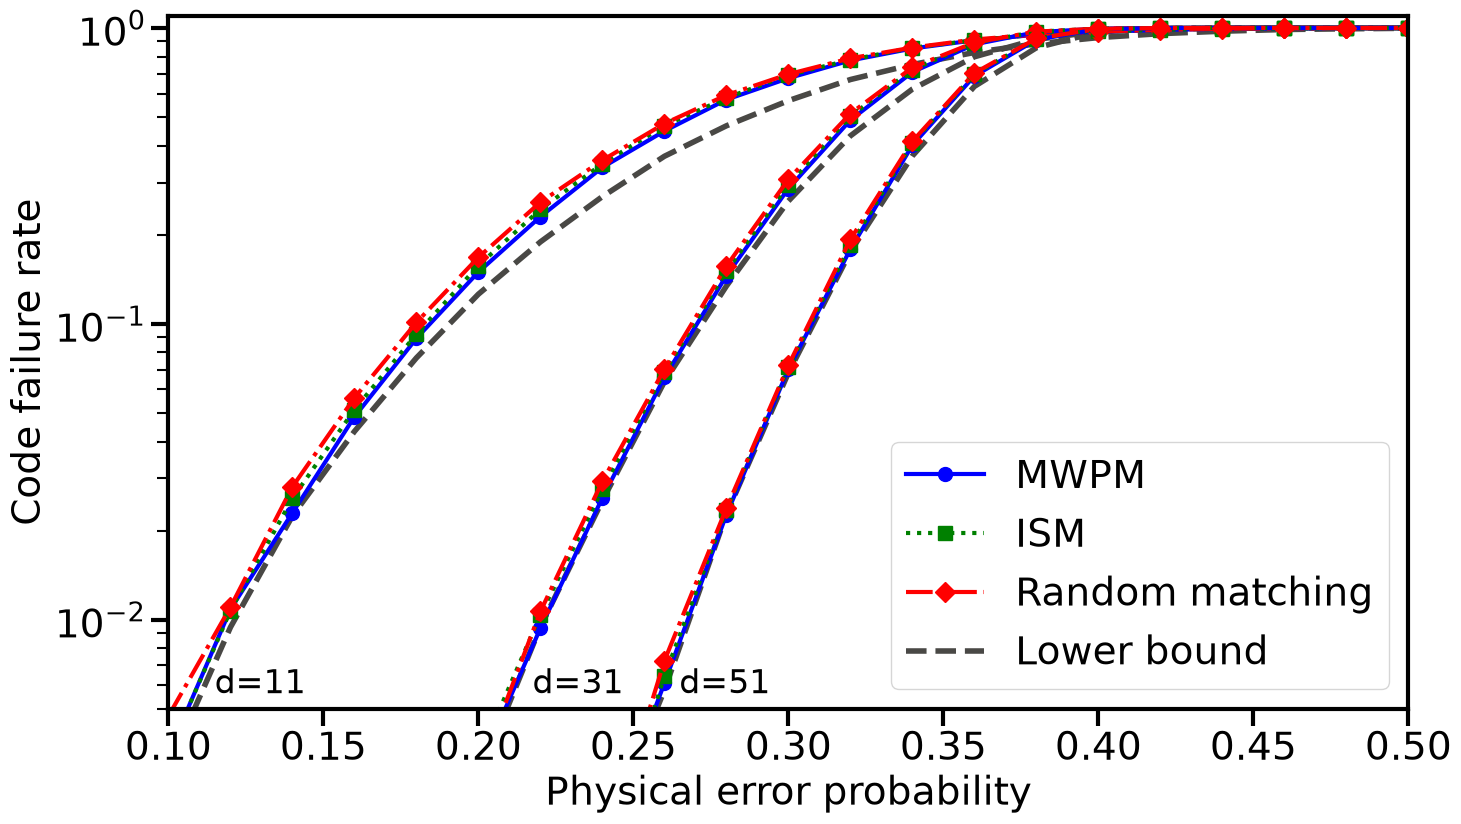

In [10]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_matching_benchmark(data, ax, save_path='Fig-4.pdf')